# MyGate AI — EDA and error analysis (v1)

Notebook **for the report**. It only reads existing files:

| Source | What is read from it |
|---|---|
| `data/clean.parquet` | the data after cleaning (2.5M rows) |
| `data/test_v1.parquet` | the golden test set (748,682) |
| `data/test_v1_raw_labels.parquet` | `raw_label` + `source_file` for each of its rows |
| `mygate_ai/models/v1/metrics.json` · `schema.json` · `model.pkl` | v1 results |
| `../archive/*.csv` (`Label` column only) | distribution of the original labels before mapping |

**It does not train, and it writes nothing to `data/` or `models/`.** Its only output: `reports/figures/*.png`.

In [1]:
import json
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

T0 = time.time()

# Run from the project root whatever the cwd is
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, ROOT)

FIGS = "reports/figures"
os.makedirs(FIGS, exist_ok=True)

plt.style.use("seaborn-v0_8-darkgrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

PALETTE = {"benign": "#2ecc71", "portscan": "#e67e22", "dos": "#e74c3c",
           "brute_force": "#9b59b6"}


def save(fig, name):
    path = os.path.join(FIGS, name)
    fig.savefig(path)
    print("→", path)


CLEAN = "data/clean.parquet"
GOLDEN = "data/test_v1.parquet"
RAWMETA = "data/test_v1_raw_labels.parquet"
MODEL_DIR = "mygate_ai/models/v1"

for p in (GOLDEN, RAWMETA, f"{MODEL_DIR}/metrics.json"):
    assert os.path.isfile(p), f"missing: {p}"

metrics = json.load(open(f"{MODEL_DIR}/metrics.json", encoding="utf-8"))
schema = json.load(open(f"{MODEL_DIR}/schema.json", encoding="utf-8"))
FEATURES = schema["features"]
CLASSES = schema["classes"]
print("ROOT:", ROOT)
print("model:", schema["model_version"], "|", len(FEATURES), "features |", CLASSES)

ROOT: C:\Users\COMPUMARTS\Desktop\IDS proj\mygate-ai
model: v1 | 69 features | ['benign', 'brute_force', 'dos', 'portscan']


---

## 1) The data

In [2]:
# Original label distribution — Label column only from the CSVs (read-only)
from mygate_ai.features import feature_list  # noqa: E402

import yaml  # noqa: E402

cfg = yaml.safe_load(open("config.yaml", encoding="utf-8"))
LABEL_MAP = cfg["label_map"]
FEATS = feature_list(cfg)

ARCHIVE = cfg["sources"]["cic2017"]["path"]
if os.path.isdir(ARCHIVE):
    files = sorted(f for f in os.listdir(ARCHIVE) if f.endswith(".csv"))
    parts = []
    for f in files:
        s = pd.read_csv(os.path.join(ARCHIVE, f), usecols=[" Label"], low_memory=False)
        parts.append(pd.DataFrame({"raw_label": s[" Label"].astype(str).str.strip(),
                                   "source_file": f.replace(".pcap_ISCX.csv", "")
                                                   .replace("-WorkingHours", "")}))
    raw_all = pd.concat(parts, ignore_index=True)
    print(f"{len(raw_all):,} rows from {len(files)} files")
else:
    raw_all = None
    print(f"⚠️ {ARCHIVE} not found — skipping the original label distribution.")

2,830,743 rows from 8 files


→ reports/figures\01_original_labels.png


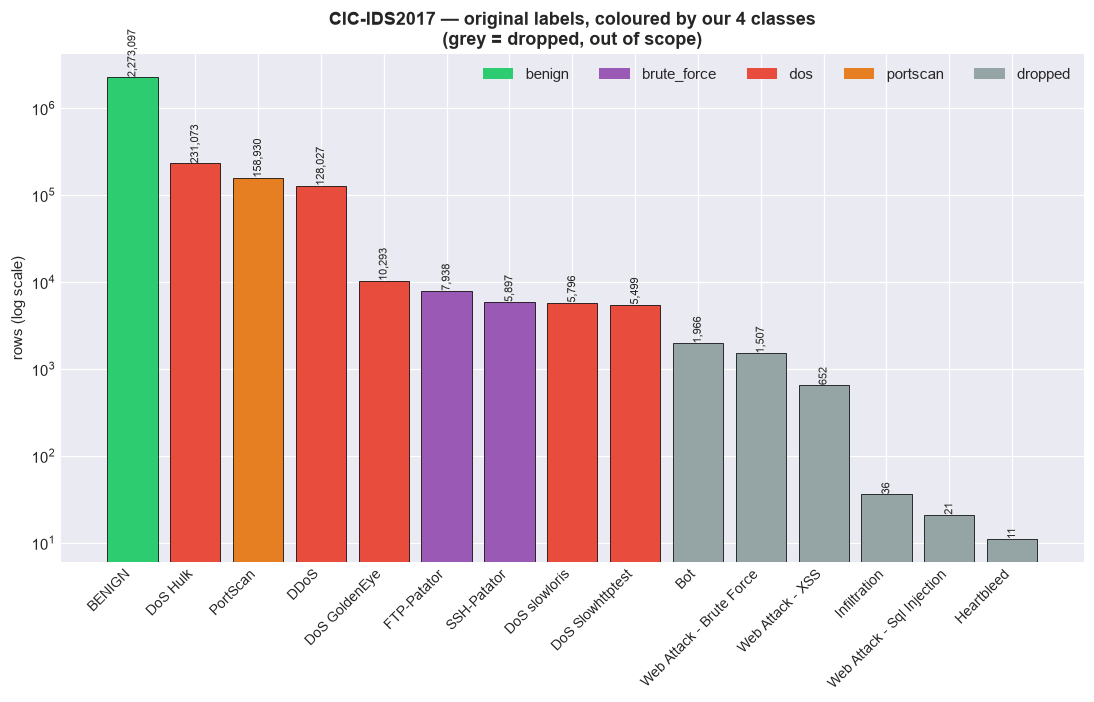

In [3]:
if raw_all is not None:
    counts = raw_all["raw_label"].value_counts()
    # The broken character in the Web Attack labels exists in no font — clean it for display
    counts.index = [s.replace("\uFFFD", "-") for s in counts.index]
    mapped = counts.index.map(lambda x: LABEL_MAP.get(x, "DROPPED"))
    colors = [PALETTE.get(m, "#95a5a6") for m in mapped]

    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(range(len(counts)), counts.values, color=colors, edgecolor="black", lw=0.5)
    ax.set_yscale("log")
    ax.set_xticks(range(len(counts)))
    ax.set_xticklabels(counts.index, rotation=45, ha="right", fontsize=9)
    ax.set_ylabel("rows (log scale)")
    ax.set_title("CIC-IDS2017 — original labels, coloured by our 4 classes\n"
                 "(grey = dropped, out of scope)", fontweight="bold")
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7, rotation=90)
    handles = [plt.Rectangle((0, 0), 1, 1, fc=PALETTE[c]) for c in CLASSES]
    handles.append(plt.Rectangle((0, 0), 1, 1, fc="#95a5a6"))
    ax.legend(handles, CLASSES + ["dropped"], ncol=5, loc="upper right")
    save(fig, "01_original_labels.png")
    plt.show()

In [4]:
if raw_all is not None:
    rows = []
    for lbl, n in raw_all["raw_label"].value_counts().items():
        rows.append({"raw_label": lbl, "rows": n,
                     "→ class": LABEL_MAP.get(lbl, "— dropped —")})
    tbl = pd.DataFrame(rows)
    print("15 original labels → 4 classes\n")
    print(tbl.to_string(index=False))

    dropped = tbl[tbl["→ class"] == "— dropped —"]
    print(f"\nDropped as out-of-scope: {dropped['rows'].sum():,} rows "
          f"({dropped['rows'].sum() / len(raw_all) * 100:.3f}%)")
    print("Reason: Web attacks and Heartbleed are Suricata's job (payload); "
          "Bot and Infiltration are a documented v1 limitation.")

15 original labels → 4 classes

                 raw_label    rows     → class
                    BENIGN 2273097      benign
                  DoS Hulk  231073         dos
                  PortScan  158930    portscan
                      DDoS  128027         dos
             DoS GoldenEye   10293         dos
               FTP-Patator    7938 brute_force
               SSH-Patator    5897 brute_force
             DoS slowloris    5796         dos
          DoS Slowhttptest    5499         dos
                       Bot    1966 — dropped —
  Web Attack � Brute Force    1507 — dropped —
          Web Attack � XSS     652 — dropped —
              Infiltration      36 — dropped —
Web Attack � Sql Injection      21 — dropped —
                Heartbleed      11 — dropped —

Dropped as out-of-scope: 4,193 rows (0.148%)
Reason: Web attacks and Heartbleed are Suricata's job (payload); Bot and Infiltration are a documented v1 limitation.


raw rows                 : 2,830,743
after dropping out-of-scope: 2,826,550
after dedup              : 2,495,605
identical features, different labels: 1,438


→ reports/figures\02_class_distribution.png


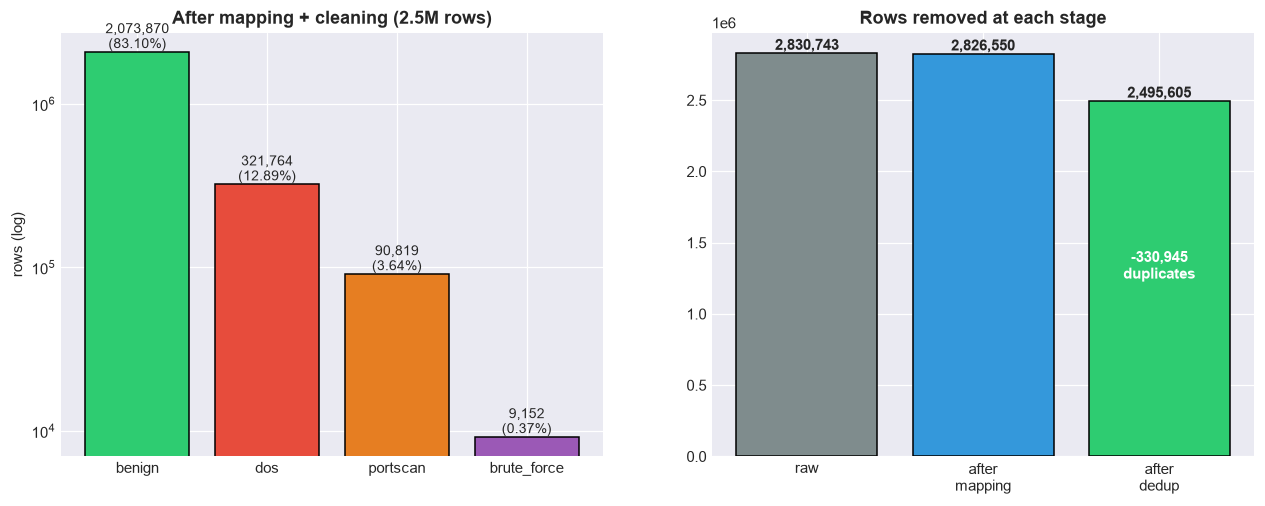

In [5]:
# Dedup and conflicting rows — from clean.parquet
# Read only the columns we need, and use a hash instead of duplicated() over 69 columns
N_RAW = len(raw_all) if raw_all is not None else 2_830_743
clean = pd.read_parquet(CLEAN, columns=FEATS + ["label"])
key = pd.util.hash_pandas_object(clean[FEATS], index=False)
conflicts = int(key.duplicated(keep=False).sum())

print(f"raw rows                 : {N_RAW:,}")
print(f"after dropping out-of-scope: {len(clean) + 330_945:,}")
print(f"after dedup              : {len(clean):,}")
print(f"identical features, different labels: {conflicts:,}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d = clean["label"].value_counts()
axes[0].bar(d.index, d.values, color=[PALETTE[c] for c in d.index], edgecolor="black")
axes[0].set_yscale("log")
axes[0].set_title("After mapping + cleaning (2.5M rows)", fontweight="bold")
axes[0].set_ylabel("rows (log)")
for i, v in enumerate(d.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(clean) * 100:.2f}%)", ha="center",
                 va="bottom", fontsize=9)

stages = ["raw", "after\nmapping", "after\ndedup"]
vals = [N_RAW, len(clean) + 330_945, len(clean)]
axes[1].bar(stages, vals, color=["#7f8c8d", "#3498db", "#2ecc71"], edgecolor="black")
axes[1].set_title("Rows removed at each stage", fontweight="bold")
for i, v in enumerate(vals):
    axes[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontweight="bold")
axes[1].text(2, vals[2] * 0.5, f"-330,945\nduplicates", ha="center", color="white",
             fontweight="bold")
save(fig, "02_class_distribution.png")
plt.show()
del clean, key

---

## 2) The model

In [6]:
import joblib  # noqa: E402

from mygate_ai.features import build_features  # noqa: E402

golden = pd.read_parquet(GOLDEN)
meta = pd.read_parquet(RAWMETA)
assert len(golden) == len(meta), "the two files are not aligned!"

model = joblib.load(f"{MODEL_DIR}/model.pkl")
X = build_features(golden, cfg)[FEATURES].astype("float32")
y = golden["label"].astype(str).to_numpy()

proba = model.predict_proba(X)
bi = CLASSES.index("benign")
p_attack = 1.0 - proba[:, bi]
pred = np.array([CLASSES[i] for i in proba.argmax(axis=1)])

raw = meta["raw_label"].astype(str).to_numpy()
src = meta["source_file"].astype(str).to_numpy()
conflict = meta["feature_conflict"].to_numpy().astype(bool)

missed = (y != "benign") & (pred == "benign")
fp = (y == "benign") & (pred != "benign")
print(f"{len(golden):,} flow | {int(missed.sum())} missed attacks | {int(fp.sum())} FP")

748,682 flow | 62 missed attacks | 575 FP


→ reports/figures\03_confusion_matrix.png


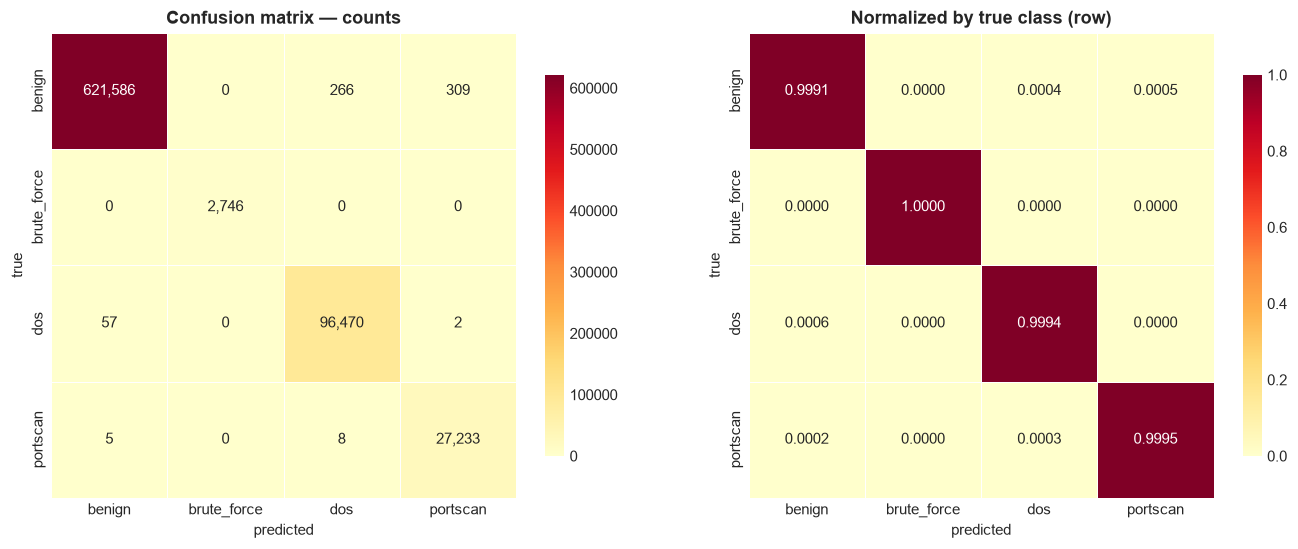

In [7]:
from sklearn.metrics import confusion_matrix  # noqa: E402

cm = confusion_matrix(y, pred, labels=CLASSES)
cmn = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, data, fmt, title in (
    (axes[0], cm, ",d", "Confusion matrix — counts"),
    (axes[1], cmn, ".4f", "Normalized by true class (row)"),
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap="YlOrRd", square=True,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
                cbar_kws={"shrink": 0.75}, linewidths=0.5, linecolor="white")
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title, fontweight="bold")
save(fig, "03_confusion_matrix.png")
plt.show()

→ reports/figures\04_per_class.png


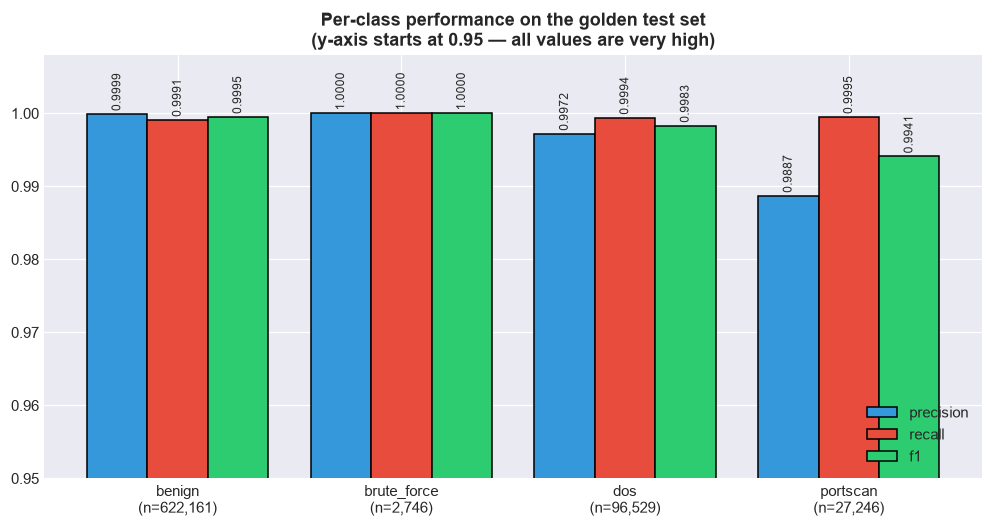

In [8]:
pc = pd.DataFrame(metrics["per_class"]).T.loc[CLASSES]
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(CLASSES))
w = 0.27
for i, (m, c) in enumerate([("precision", "#3498db"), ("recall", "#e74c3c"),
                            ("f1", "#2ecc71")]):
    b = ax.bar(x + (i - 1) * w, pc[m], w, label=m, color=c, edgecolor="black")
    ax.bar_label(b, fmt="%.4f", fontsize=8, rotation=90, padding=2)
ax.set_xticks(x)
ax.set_xticklabels([f"{c}\n(n={int(pc.loc[c, 'support']):,})" for c in CLASSES])
ax.set_ylim(0.95, 1.008)
ax.legend(loc="lower right")
ax.set_title("Per-class performance on the golden test set\n"
             "(y-axis starts at 0.95 — all values are very high)", fontweight="bold")
save(fig, "04_per_class.png")
plt.show()

→ reports/figures\05_feature_importance.png


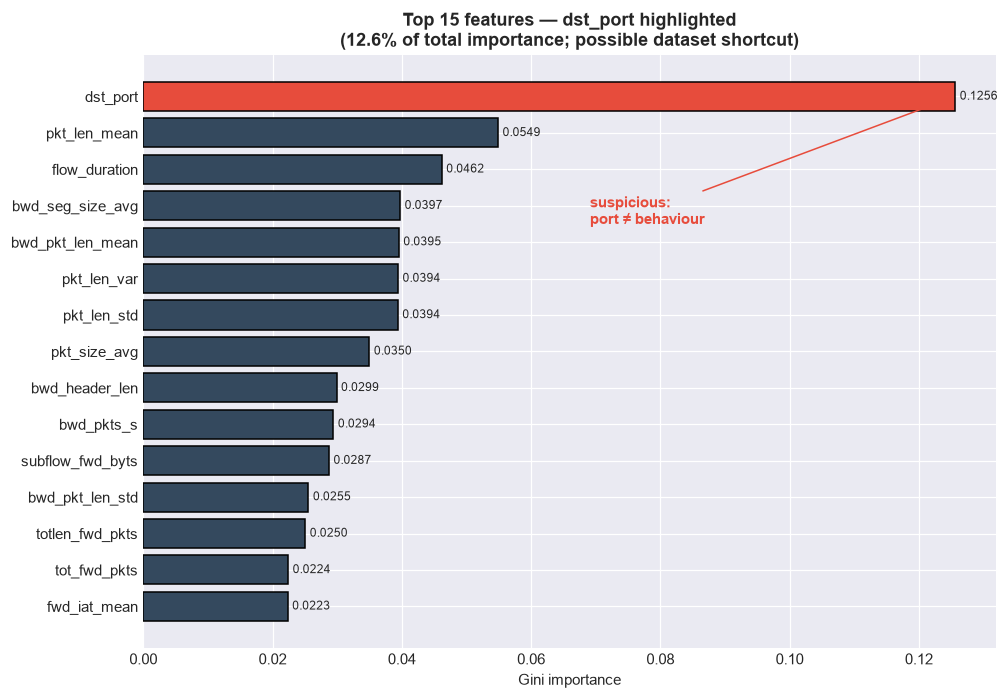

In [9]:
top = pd.DataFrame(metrics["top_features"]).head(15).iloc[::-1]
colors = ["#e74c3c" if f == "dst_port" else "#34495e" for f in top["feature"]]

fig, ax = plt.subplots(figsize=(10, 7))
b = ax.barh(top["feature"], top["importance"], color=colors, edgecolor="black")
ax.bar_label(b, fmt="%.4f", fontsize=8, padding=3)
ax.set_xlabel("Gini importance")
ax.set_title("Top 15 features — dst_port highlighted\n"
             "(12.6% of total importance; possible dataset shortcut)",
             fontweight="bold")
ax.annotate("suspicious:\nport ≠ behaviour", xy=(top["importance"].max(), 14),
            xytext=(top["importance"].max() * 0.55, 10.5), color="#e74c3c",
            fontweight="bold", arrowprops={"arrowstyle": "->", "color": "#e74c3c"})
save(fig, "05_feature_importance.png")
plt.show()

→ reports/figures\06_thresholds.png


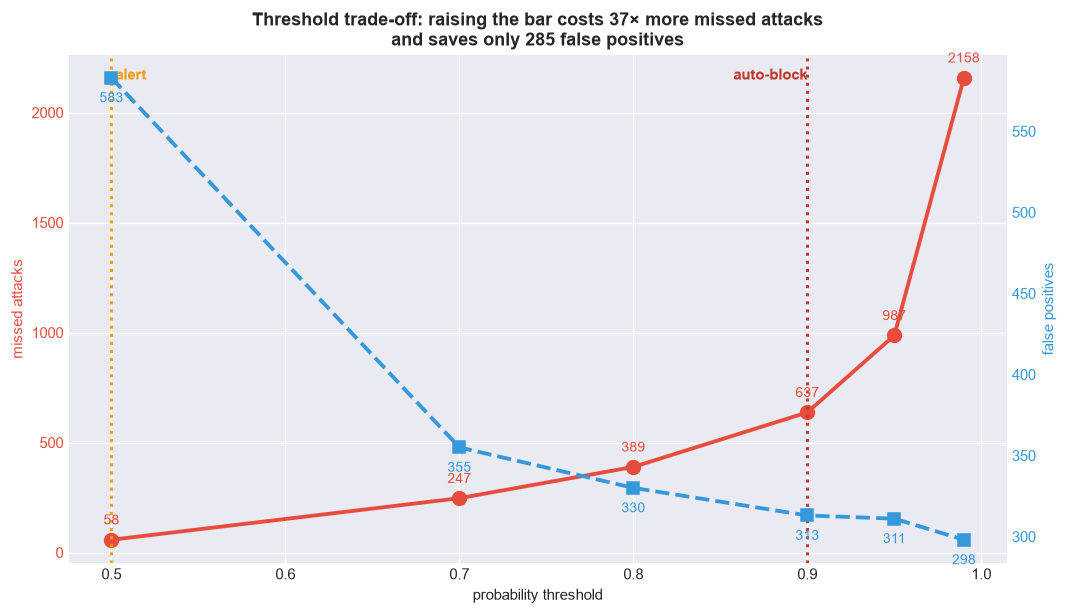

 threshold  detection_rate  missed_attacks      fpr  false_positives
      0.50         0.99954              58 0.000937              583
      0.70         0.99805             247 0.000571              355
      0.80         0.99693             389 0.000530              330
      0.90         0.99497             637 0.000503              313
      0.95         0.99220             987 0.000500              311
      0.99         0.98294            2158 0.000479              298


In [10]:
th = pd.DataFrame(metrics["thresholds"])

fig, ax1 = plt.subplots(figsize=(11, 6))
ax1.plot(th["threshold"], th["missed_attacks"], "o-", color="#e74c3c", lw=2.5,
         ms=9, label="missed attacks")
ax1.set_xlabel("probability threshold")
ax1.set_ylabel("missed attacks", color="#e74c3c")
ax1.tick_params(axis="y", labelcolor="#e74c3c")
for _, r in th.iterrows():
    ax1.annotate(f"{int(r['missed_attacks'])}", (r["threshold"], r["missed_attacks"]),
                 textcoords="offset points", xytext=(0, 10), ha="center",
                 color="#e74c3c", fontsize=9)

ax2 = ax1.twinx()
ax2.plot(th["threshold"], th["false_positives"], "s--", color="#3498db", lw=2.5,
         ms=8, label="false positives")
ax2.set_ylabel("false positives", color="#3498db")
ax2.tick_params(axis="y", labelcolor="#3498db")
ax2.grid(False)
for _, r in th.iterrows():
    ax2.annotate(f"{int(r['false_positives'])}", (r["threshold"], r["false_positives"]),
                 textcoords="offset points", xytext=(0, -16), ha="center",
                 color="#3498db", fontsize=9)

ax1.axvline(0.5, color="#f39c12", ls=":", lw=2)
ax1.axvline(0.9, color="#c0392b", ls=":", lw=2)
ax1.text(0.5, ax1.get_ylim()[1] * 0.95, " alert", color="#f39c12", fontweight="bold")
ax1.text(0.9, ax1.get_ylim()[1] * 0.95, " auto-block", color="#c0392b",
         fontweight="bold", ha="right")
ax1.set_title("Threshold trade-off: raising the bar costs 37× more missed attacks\n"
              "and saves only 285 false positives", fontweight="bold")
save(fig, "06_thresholds.png")
plt.show()
print(th.to_string(index=False))

---

## 3) Error analysis

→ reports/figures\07_recall_per_raw_label.png


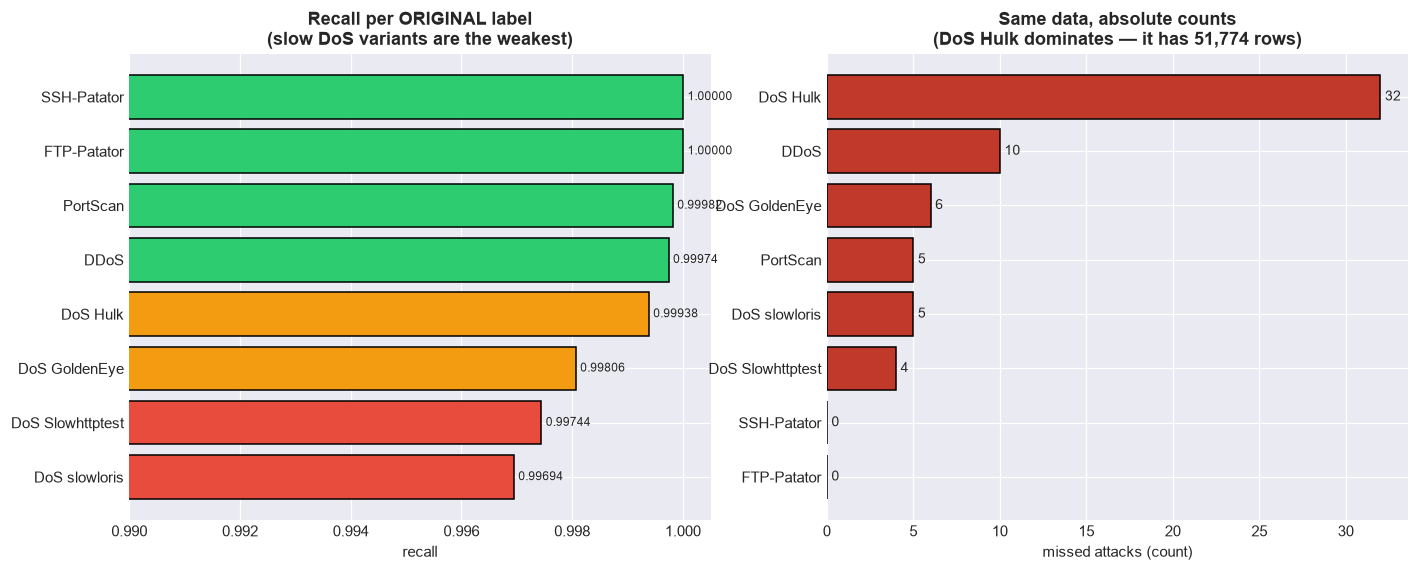

                  support  caught  missed    recall
raw                                                
DoS slowloris        1636    1631       5  0.996944
DoS Slowhttptest     1563    1559       4  0.997441
DoS GoldenEye        3096    3090       6  0.998062
DoS Hulk            51774   51742      32  0.999382
DDoS                38460   38450      10  0.999740
PortScan            27246   27241       5  0.999816
FTP-Patator          1743    1743       0  1.000000
SSH-Patator          1003    1003       0  1.000000


In [11]:
atk = y != "benign"
rec = (pd.DataFrame({"raw": raw[atk], "caught": (pred != "benign")[atk]})
       .groupby("raw")["caught"].agg(support="count", caught="sum"))
rec["missed"] = rec["support"] - rec["caught"]
rec["recall"] = rec["caught"] / rec["support"]
rec = rec.sort_values("recall")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
c = ["#e74c3c" if r < 0.998 else "#f39c12" if r < 0.9995 else "#2ecc71"
     for r in rec["recall"]]
b = axes[0].barh(rec.index, rec["recall"], color=c, edgecolor="black")
axes[0].bar_label(b, fmt="%.5f", fontsize=8, padding=3)
axes[0].set_xlim(0.99, 1.0005)
axes[0].set_xlabel("recall")
axes[0].set_title("Recall per ORIGINAL label\n(slow DoS variants are the weakest)",
                  fontweight="bold")

b2 = axes[1].barh(rec.sort_values("missed").index,
                  rec.sort_values("missed")["missed"], color="#c0392b",
                  edgecolor="black")
axes[1].bar_label(b2, fontsize=9, padding=3)
axes[1].set_xlabel("missed attacks (count)")
axes[1].set_title("Same data, absolute counts\n(DoS Hulk dominates — it has 51,774 rows)",
                  fontweight="bold")
save(fig, "07_recall_per_raw_label.png")
plt.show()
print(rec.to_string())

→ reports/figures\08_fp_by_source_file.png


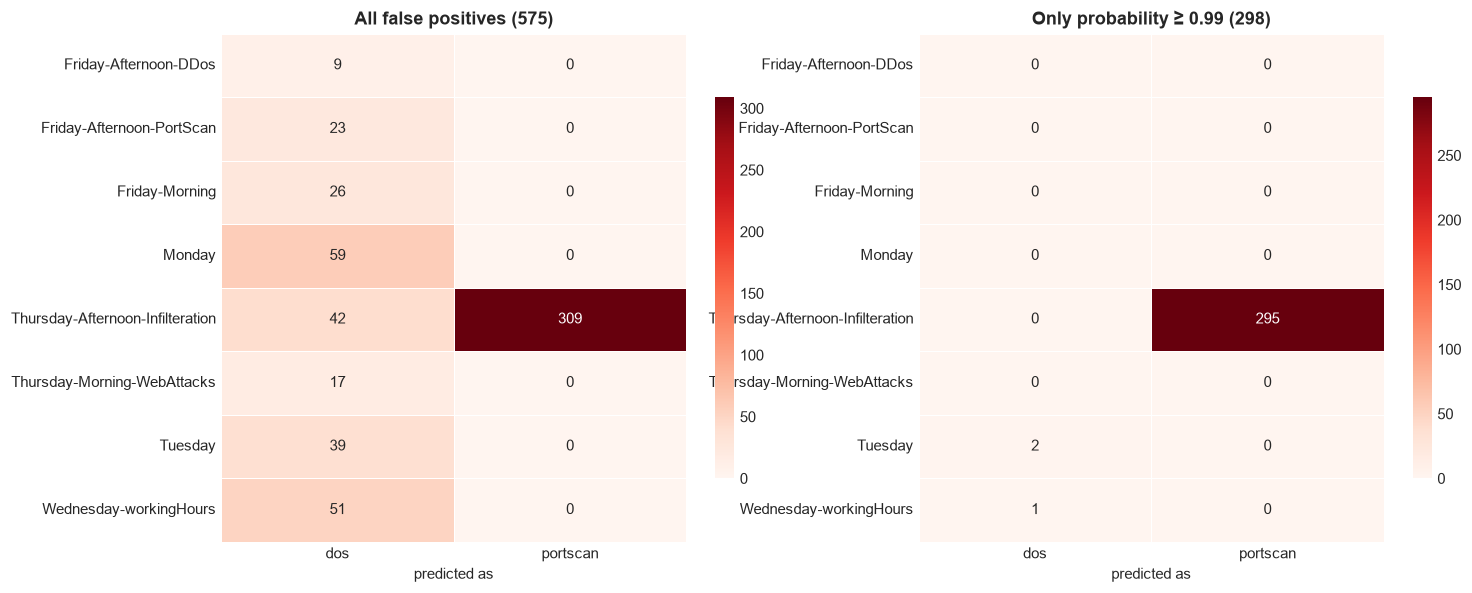

col_0                             dos  portscan
row_0                                          
Friday-Afternoon-DDos               9         0
Friday-Afternoon-PortScan          23         0
Friday-Morning                     26         0
Monday                             59         0
Thursday-Afternoon-Infilteration   42       309
Thursday-Morning-WebAttacks        17         0
Tuesday                            39         0
Wednesday-workingHours             51         0


In [12]:
sure = fp & (p_attack >= 0.99)
ct_all = pd.crosstab(pd.Series(src[fp]), pd.Series(pred[fp]))
ct_sure = pd.crosstab(pd.Series(src[sure]), pd.Series(pred[sure]))
ct_sure = ct_sure.reindex(index=ct_all.index, columns=ct_all.columns, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, data, title in (
    (axes[0], ct_all, f"All false positives ({int(fp.sum())})"),
    (axes[1], ct_sure, f"Only probability ≥ 0.99 ({int(sure.sum())})"),
):
    sns.heatmap(data, annot=True, fmt=",d", cmap="Reds", ax=ax, linewidths=0.5,
                linecolor="white", cbar_kws={"shrink": 0.75})
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("predicted as")
    ax.set_ylabel("")
save(fig, "08_fp_by_source_file.png")
plt.show()
print(ct_all.to_string())

→ reports/figures\09_fp_probability_hist.png


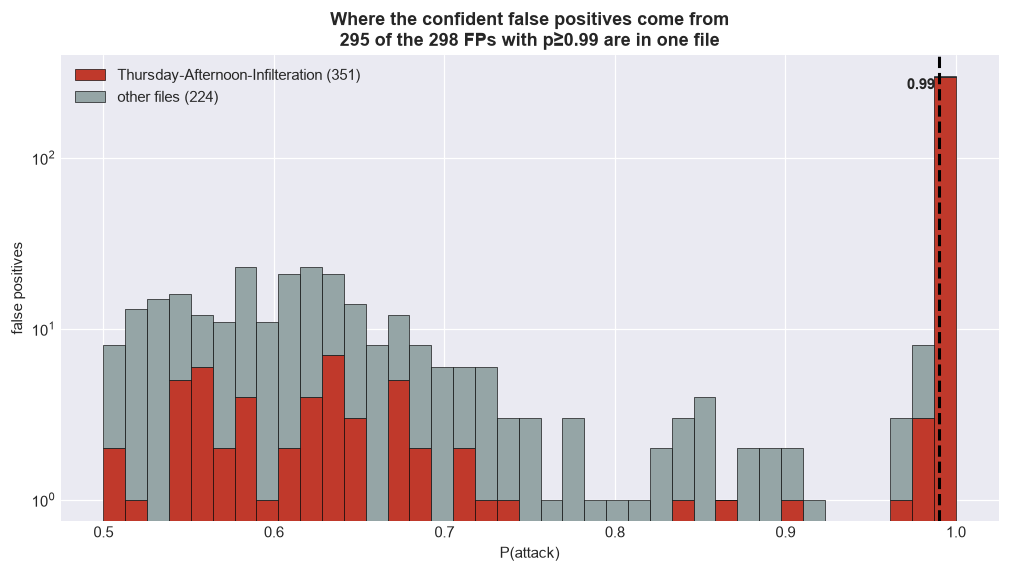

In [13]:
THU = "Thursday-Afternoon-Infilteration"
is_thu = src == THU
fig, ax = plt.subplots(figsize=(11, 5.5))
bins = np.linspace(0.5, 1.0, 40)
ax.hist([p_attack[fp & is_thu], p_attack[fp & ~is_thu]], bins=bins, stacked=True,
        color=["#c0392b", "#95a5a6"], edgecolor="black", lw=0.4,
        label=[f"{THU} ({int((fp & is_thu).sum())})",
               f"other files ({int((fp & ~is_thu).sum())})"])
ax.axvline(0.99, color="black", ls="--", lw=2)
ax.text(0.99, ax.get_ylim()[1] * 0.8, " 0.99 ", ha="right", fontweight="bold")
ax.set_xlabel("P(attack)")
ax.set_ylabel("false positives")
ax.set_yscale("log")
ax.legend()
ax.set_title("Where the confident false positives come from\n"
             f"{int((sure & is_thu).sum())} of the {int(sure.sum())} FPs with p≥0.99 "
             "are in one file", fontweight="bold")
save(fig, "09_fp_probability_hist.png")
plt.show()

Median per feature:



                   Thu FP → portscan  Friday PortScan  ordinary benign
tot_fwd_pkts                     1.0              1.0              2.0
tot_bwd_pkts                     1.0              1.0              2.0
flow_duration                   51.0             51.0          47855.0
totlen_fwd_pkts                  2.0              2.0             69.0
init_fwd_win_byts             1024.0           1024.0            130.0


→ reports/figures\10_profile_comparison.png


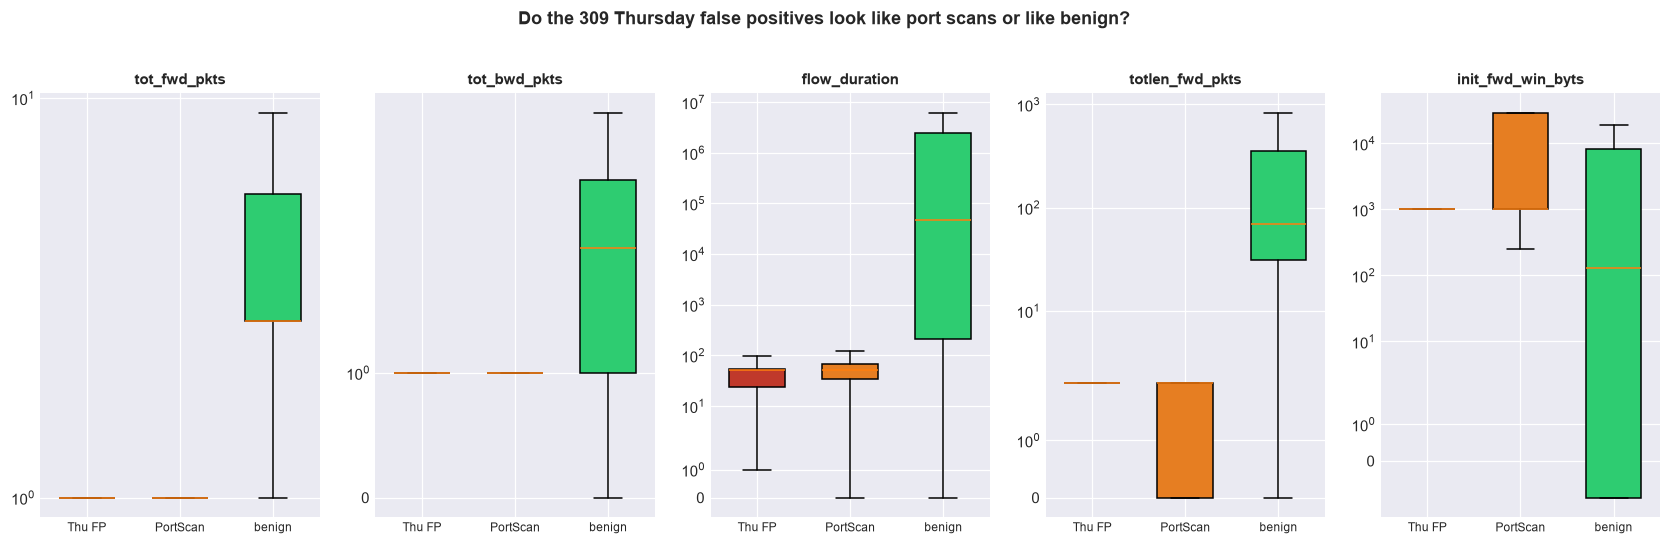

In [14]:
PROFILE = ["tot_fwd_pkts", "tot_bwd_pkts", "flow_duration", "totlen_fwd_pkts",
           "init_fwd_win_byts"]

g_thu_fp = fp & is_thu & (pred == "portscan")
g_ps = (y == "portscan") & (src == "Friday-Afternoon-PortScan")
g_ben = (y == "benign") & ~is_thu & ~fp
rng = np.random.default_rng(42)
idx_ben = rng.choice(np.flatnonzero(g_ben), size=5000, replace=False)
idx_ps = rng.choice(np.flatnonzero(g_ps), size=5000, replace=False)

groups = {
    f"Thu FP → portscan\n(n={int(g_thu_fp.sum())})": golden.loc[g_thu_fp, PROFILE],
    "Friday PortScan\n(sample 5,000)": golden.iloc[idx_ps][PROFILE],
    "ordinary benign\n(sample 5,000)": golden.iloc[idx_ben][PROFILE],
}

print("Median per feature:\n")
med = pd.DataFrame({k.split(chr(10))[0]: v.median() for k, v in groups.items()})
print(med.to_string())

fig, axes = plt.subplots(1, len(PROFILE), figsize=(19, 5))
cols = ["#c0392b", "#e67e22", "#2ecc71"]
for ax, feat in zip(axes, PROFILE):
    bp = ax.boxplot([g[feat].to_numpy() for g in groups.values()], patch_artist=True,
                    showfliers=False, widths=0.6)
    for patch, c in zip(bp["boxes"], cols):
        patch.set_facecolor(c)
    ax.set_xticklabels(["Thu FP", "PortScan", "benign"], fontsize=8)
    ax.set_title(feat, fontweight="bold", fontsize=10)
    if golden[feat].max() > 1000:
        ax.set_yscale("symlog")
fig.suptitle("Do the 309 Thursday false positives look like port scans or like benign?",
             fontweight="bold", y=1.03)
save(fig, "10_profile_comparison.png")
plt.show()

---

## 4) FPR table

In [15]:
n_benign = int((y == "benign").sum())
n_thu_ben = int(((y == "benign") & is_thu).sum())
fp_thu = int((fp & is_thu).sum())
fp_other = int((fp & ~is_thu).sum())
fp_mon = int((fp & (src == "Monday")).sum())
n_mon = int(((y == "benign") & (src == "Monday")).sum())

rows = [
    {"case": "official — whole golden set", "FP": int(fp.sum()),
     "benign flows": n_benign, "FPR": fp.sum() / n_benign, "type": "measured"},
    {"case": f"excluding {THU}", "FP": fp_other,
     "benign flows": n_benign - n_thu_ben,
     "FPR": fp_other / (n_benign - n_thu_ben), "type": "⚠️ estimate"},
    {"case": "Monday only (an all-benign day)", "FP": fp_mon,
     "benign flows": n_mon, "FPR": fp_mon / n_mon, "type": "measured"},
]
t = pd.DataFrame(rows)
t["FPR"] = t["FPR"].map(lambda v: f"{v:.6f}")
print(t.to_string(index=False))

print()
print("!! The second row is **an estimate, not a measurement**.")
print(f"   It assumes that the {fp_thu} FPs in {THU}")
print("   are all label noise, which is **not proven** — proving it needs the original PCAP.")
print(f"   The official number for delivery is the first row: {fp.sum() / n_benign:.5f}")
print()
print("   Monday is an all-benign day per the dataset description, so its "
      f"{fp_mon} FPs are the closest thing")
print("   we have to a clean error rate.")

                                    case   FP  benign flows       FPR         type
         official — whole golden set  575        622161  0.000924     measured
excluding Thursday-Afternoon-Infilteration  224   549196  0.000408  ⚠️ estimate
         Monday only (an all-benign day)   59        147804  0.000399     measured

!! The second row is **an estimate, not a measurement**.
   It assumes that the 351 FPs in Thursday-Afternoon-Infilteration
   are all label noise, which is **not proven** — proving it needs the original PCAP.
   The official number for delivery is the first row: 0.00092

   Monday is an all-benign day per the dataset description, so its 59 FPs are the closest thing
   we have to a clean error rate.


---

## 5) Limitations that must be stated in the report

**1) Label noise in `Thursday-Afternoon-Infilteration`.**
295 of the 298 false positives with probability ≥ 0.99 are in this file, and all of them are
classified `portscan`. The CIC-IDS2017 description says the Thursday-afternoon scenario includes
the compromised host (Win Vista) running a **port scan of the internal network**, and that scan is
**not labelled** `PortScan`. So the model has most likely caught a real scan that is labelled `BENIGN`.
This is **consistent with the dataset description, but proving it needs the original PCAP** — it is
not proven here. (Engelen et al. 2021 report similar labelling errors in CIC-IDS2017.)

Also, 220 of the 575 FPs (38%) are rows **identical in all 69 features** to other rows with a
different label — the model cannot tell them apart at all.

**2) `dst_port` shortcut.** The top feature at 12.6%. Almost all 266 `dos` FPs are on port 80, and
every DoS attack in the dataset targets port 80. So the model is probably learning "port + pattern",
not the attack behaviour alone. A v1.1 experiment (without `dst_port`) on the same golden set will
measure this.

**3) The feature-extraction tool is not the same.** Training uses CSVs from
**CICFlowMeter (Java)**, while live traffic comes from **`cicflowmeter` (Python)** — an independent
reimplementation. They can differ in `flow_duration` units, flow timeout and the definition of
`init_win_byts`. **All these numbers are a theoretical upper bound** until we compare against a lab
CSV from the network team. *(Since confirmed in lab testing — see `KNOWN_ISSUES.md`.)*

**4) No coverage for**: SQLi · XSS · web brute force · Heartbleed (Suricata's job),
and Bot · Infiltration (a documented v1 limitation).

**5) The model sees one isolated flow** — no history and no relation between flows,
so a slow attack spread over many flows can slip through.

In [16]:
print("Figures in reports/figures/:")
for f in sorted(os.listdir(FIGS)):
    print(f"  {f:38s} {os.path.getsize(os.path.join(FIGS, f)) / 1024:7.1f} KB")
print(f"\n⏱️  Total time: {time.time() - T0:.1f} s")

Figures in reports/figures/:
  01_original_labels.png                    86.5 KB
  02_class_distribution.png                 65.6 KB
  03_confusion_matrix.png                   82.6 KB
  04_per_class.png                          58.3 KB
  05_feature_importance.png                 89.7 KB
  06_thresholds.png                         97.8 KB
  07_recall_per_raw_label.png               85.6 KB
  08_fp_by_source_file.png                 104.7 KB
  09_fp_probability_hist.png                41.8 KB
  10_profile_comparison.png                 59.9 KB

⏱️  Total time: 20.8 s
